# Multimodal Deep Learning for ED Triage Risk Prediction
### H9MLAI CA2 — Prasanth Oddepally (x25205595), National College of Ireland
**RQ1** structured vitals vs vitals+chief-complaint/history · 
**RQ2** agreement with nurse ESI ·
**RQ3**  fairness across age/gender.

## Imports

In [18]:
import numpy as np, pandas as pd, warnings, gc
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score,f1_score,precision_score,recall_score,
    accuracy_score,confusion_matrix,classification_report,cohen_kappa_score)
import matplotlib.pyplot as plt
SEED=42; np.random.seed(SEED)
print('ready')

ready


## Data Loading 

In [19]:
DATA_PATH = r"C:\Users\msi\OneDrive\Desktop\ML CA\ML CA 2\5v_cleandf.csv"
SAMPLE_FRAC = 1.00        # this file is small (109k rows); use 1.0 = all rows. Lower to 0.5 if RAM is tight

all_cols = pd.read_csv(DATA_PATH, nrows=0).columns.tolist()
print("Total columns in file:", len(all_cols))

# Column groups (verified against the real file)
admin = ['dep_name','esi','age','gender','ethnicity','race','disposition',
         'arrivalmode','arrivalmonth','arrivalday','arrivalhour_bin','previousdispo']
vitals = ['triage_vital_hr','triage_vital_sbp','triage_vital_dbp',
          'triage_vital_rr','triage_vital_o2','triage_vital_temp']
vitals = [c for c in vitals if c in all_cols]
cc_cols = [c for c in all_cols if c.lower().startswith('cc_')]   # chief-complaint flags
# disease-history flags = everything else that's not admin/index/vital/cc
used = set(admin+vitals+cc_cols+['Unnamed: 0'])
history_cols = [c for c in all_cols if c not in used]

usecols = [c for c in admin+vitals+cc_cols+history_cols if c in all_cols]
print(f"Loading {len(usecols)} cols | vitals={len(vitals)} cc={len(cc_cols)} history={len(history_cols)}")

parts=[]
for chunk in pd.read_csv(DATA_PATH, usecols=usecols, chunksize=50000):
    parts.append(chunk.sample(frac=SAMPLE_FRAC, random_state=SEED))
df = pd.concat(parts, ignore_index=True); del parts; gc.collect()
print("Sample shape:", df.shape)

Total columns in file: 972
Loading 972 cols | vitals=6 cc=200 history=754
Sample shape: (109594, 972)


## Understanding  of Data (EDA)

Admission rate: 0.311


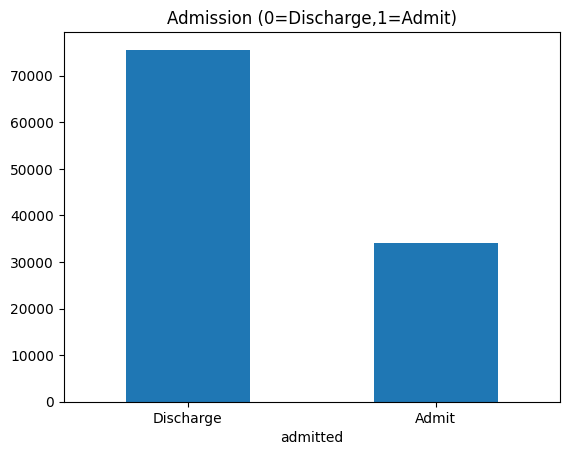

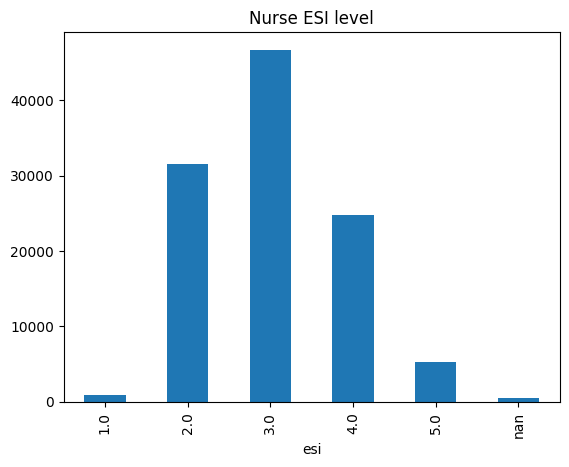

       triage_vital_hr  triage_vital_sbp  triage_vital_dbp  triage_vital_rr  \
count     76172.000000      75784.000000      75747.000000     75280.000000   
mean         85.370283        134.062725         80.527871        17.645243   
std          16.678744         21.712204         13.975244         2.000519   
min          30.000000         53.000000         25.000000         8.000000   
25%          74.000000        119.000000         71.000000        16.000000   
50%          84.000000        132.000000         80.000000        18.000000   
75%          96.000000        146.000000         89.000000        18.000000   
max         221.000000        274.000000        189.000000        69.000000   

       triage_vital_o2  triage_vital_temp  
count     56161.000000       72858.000000  
mean         97.217530          98.087627  
std           2.002543           0.776688  
min          60.000000          93.000000  
25%          96.000000          97.700000  
50%          98.000000  

In [ ]:
# Target
df['admitted'] = df['disposition'].astype(str).str.contains('Admit').astype(int)
print("Admission rate:", round(df['admitted'].mean(),3))
df['admitted'].value_counts().plot(kind='bar',title='Admission (0=Discharge,1=Admit)')
plt.xticks([0,1],['Discharge','Admit'],rotation=0); plt.show()
df['admitted'].value_counts().rename_axis('admitted').reset_index(name='count').to_csv('admission_counts.csv',index=False)

# ESI distribution (held for RQ2)
df['esi'].value_counts(dropna=False).sort_index().plot(kind='bar',title='Nurse ESI level')
plt.show()
df['esi'].value_counts(dropna=False).sort_index().rename_axis('esi').reset_index(name='count').to_csv('esi_distribution.csv',index=False)

# Vitals summary
print(df[vitals].describe())
print("\nVitals missingness:"); print(df[vitals].isna().mean().round(3))
df[vitals].describe().to_csv('vitals_summary.csv')
df[vitals].isna().mean().round(3).rename('missing_frac').to_csv('vitals_missingness.csv')

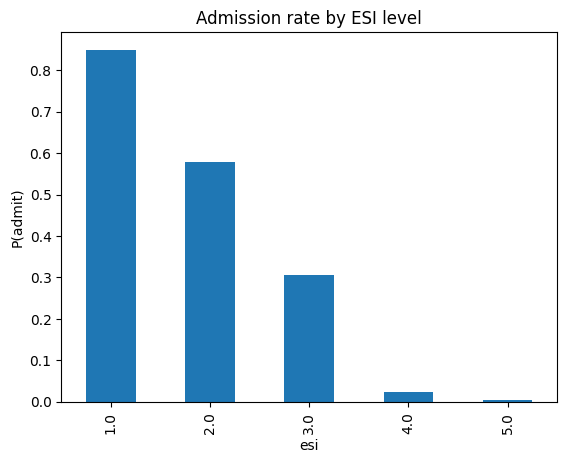

esi
1.0    0.850
2.0    0.578
3.0    0.305
4.0    0.024
5.0    0.004
Name: admitted, dtype: float64


In [ ]:
# Admission rate by ESI sanity check for behaviour of data
tab = df.groupby('esi')['admitted'].mean()
tab.plot(kind='bar',title='Admission rate by ESI level'); plt.ylabel('P(admit)'); plt.show()
print(tab.round(3))
tab.round(3).rename('admission_rate').rename_axis('esi').reset_index().to_csv('admission_rate_by_esi.csv',index=False)

##  Data Preparation
Three feature views for RQ1:
- **vitals**: triage vital signs + age/gender
- **+complaint**: vitals + chief-complaint (cc_) flags
- **+history**: vitals + complaint + full disease-history flags (the richest view)

In [22]:
df['gender_bin'] = (df['gender'].astype(str).str.upper().str[0]=='M').astype(int)

base = vitals + ['age','gender_bin']
def build(cols):
    # numeric-coerce, impute, downcast to float32 (halves memory), return contiguous array
    X = df[cols].apply(pd.to_numeric, errors='coerce')
    X = X.fillna(X.median(numeric_only=True)).fillna(0).astype('float32')
    return np.ascontiguousarray(X.values)

X_vit  = build(base)
X_cc   = build(base + cc_cols)
X_all  = build(base + cc_cols + history_cols)
y = df['admitted'].values
esi_all = df['esi'].values
print("Feature widths -> vitals:",X_vit.shape[1]," +cc:",X_cc.shape[1]," +history:",X_all.shape[1])

Feature widths -> vitals: 8  +cc: 208  +history: 962


In [23]:
# Stratified 70/15/15 split (shared indices so ESI stays aligned)
idx=np.arange(len(y))
i_tr,i_tmp=train_test_split(idx,test_size=.3,stratify=y,random_state=SEED)
i_va,i_te =train_test_split(i_tmp,test_size=.5,stratify=y[i_tmp],random_state=SEED)
def scale(X):
    s=StandardScaler().fit(X[i_tr]); return s.transform(X[i_tr]),s.transform(X[i_va]),s.transform(X[i_te])
sets={'vitals':scale(X_vit),'+complaint':scale(X_cc),'+history':scale(X_all)}
y_tr,y_va,y_te=y[i_tr],y[i_va],y[i_te]; esi_te=esi_all[i_te]
print("train",len(i_tr),"val",len(i_va),"test",len(i_te))

train 76715 val 16439 test 16440


## Modelling: baselines + DNN + TabNet

In [24]:
def sc(yt,pr,t=.5):
    p=(pr>=t).astype(int)
    return dict(AUROC=roc_auc_score(yt,pr),F1=f1_score(yt,p),
        Precision=precision_score(yt,p),Recall=recall_score(yt,p),Accuracy=accuracy_score(yt,p))
results={}; probs={}; pw=(y_tr==0).sum()/(y_tr==1).sum()

from xgboost import XGBClassifier
for name,(Xtr,Xva,Xte) in sets.items():
    lr=LogisticRegression(max_iter=1000,class_weight='balanced').fit(Xtr,y_tr)
    results[f'LogReg|{name}']=sc(y_te,lr.predict_proba(Xte)[:,1])
    xgb=XGBClassifier(n_estimators=200,max_depth=5,learning_rate=.1,scale_pos_weight=pw,
        eval_metric='logloss',random_state=SEED,n_jobs=2).fit(Xtr,y_tr)
    pr=xgb.predict_proba(Xte)[:,1]; results[f'XGB|{name}']=sc(y_te,pr); probs[f'XGB|{name}']=pr
print('baselines done')

baselines done


In [25]:
import torch, torch.nn as nn
from torch.utils.data import DataLoader,TensorDataset
torch.manual_seed(SEED)
class DNN(nn.Module):
    def __init__(s,d):
        super().__init__()
        s.net=nn.Sequential(nn.Linear(d,128),nn.ReLU(),nn.BatchNorm1d(128),nn.Dropout(.3),
            nn.Linear(128,64),nn.ReLU(),nn.Dropout(.3),nn.Linear(64,1))
    def forward(s,x): return s.net(x).squeeze(1)
def train_dnn(Xtr,Xva,ep=25):
    m=DNN(Xtr.shape[1]); cr=nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pw],dtype=torch.float32))
    op=torch.optim.Adam(m.parameters(),1e-3)
    dl=DataLoader(TensorDataset(torch.tensor(Xtr,dtype=torch.float32),
        torch.tensor(y_tr,dtype=torch.float32)),batch_size=256,shuffle=True)
    best,bs=0,None
    for _ in range(ep):
        m.train()
        for xb,yb in dl: op.zero_grad(); cr(m(xb),yb).backward(); op.step()
        m.eval()
        with torch.no_grad(): pv=torch.sigmoid(m(torch.tensor(Xva,dtype=torch.float32))).numpy()
        a=roc_auc_score(y_va,pv)
        if a>best: best,bs=a,{k:v.clone() for k,v in m.state_dict().items()}
    m.load_state_dict(bs); return m
def pb(m,X):
    m.eval()
    with torch.no_grad(): return torch.sigmoid(m(torch.tensor(X,dtype=torch.float32))).numpy()
for name,(Xtr,Xva,Xte) in sets.items():
    m=train_dnn(Xtr,Xva); pr=pb(m,Xte); results[f'DNN|{name}']=sc(y_te,pr); probs[f'DNN|{name}']=pr
print('DNN done')

DNN done


In [26]:
from pytorch_tabnet.tab_model import TabNetClassifier
for name,(Xtr,Xva,Xte) in sets.items():
    tn=TabNetClassifier(seed=SEED,verbose=0)
    tn.fit(Xtr,y_tr,eval_set=[(Xva,y_va)],eval_metric=['auc'],max_epochs=40,patience=8,batch_size=1024)
    pr=tn.predict_proba(Xte)[:,1]; results[f'TabNet|{name}']=sc(y_te,pr); probs[f'TabNet|{name}']=pr
print('TabNet done')


Early stopping occurred at epoch 29 with best_epoch = 21 and best_val_0_auc = 0.76619
Stop training because you reached max_epochs = 40 with best_epoch = 35 and best_val_0_auc = 0.83456

Early stopping occurred at epoch 25 with best_epoch = 17 and best_val_0_auc = 0.90255
TabNet done


## Latency measurement

In [ ]:
import time

latency = {}   # model -> {train_s, predict_ms_per_1k}

# We time on the richest feature view (+history) since that's the deployed setting
Xtr, Xva, Xte = sets['+history']

#  Logistic Regression 
t0=time.perf_counter()
lr=LogisticRegression(max_iter=1000,class_weight='balanced').fit(Xtr,y_tr)
t_train=time.perf_counter()-t0
t0=time.perf_counter(); _=lr.predict_proba(Xte)[:,1]; t_pred=time.perf_counter()-t0
latency['LogReg']={'train_s':round(t_train,2),'predict_ms_per_1k':round(t_pred/len(Xte)*1000*1000,2)}

# XGBoost
from xgboost import XGBClassifier
t0=time.perf_counter()
xgb=XGBClassifier(n_estimators=200,max_depth=5,learning_rate=.1,scale_pos_weight=pw,
    eval_metric='logloss',random_state=SEED,n_jobs=2).fit(Xtr,y_tr)
t_train=time.perf_counter()-t0
t0=time.perf_counter(); _=xgb.predict_proba(Xte)[:,1]; t_pred=time.perf_counter()-t0
latency['XGBoost']={'train_s':round(t_train,2),'predict_ms_per_1k':round(t_pred/len(Xte)*1000*1000,2)}

# DNN 
t0=time.perf_counter()
m=train_dnn(Xtr,Xva)
t_train=time.perf_counter()-t0
t0=time.perf_counter(); _=pb(m,Xte); t_pred=time.perf_counter()-t0
latency['DNN']={'train_s':round(t_train,2),'predict_ms_per_1k':round(t_pred/len(Xte)*1000*1000,2)}

# TabNet 
from pytorch_tabnet.tab_model import TabNetClassifier
t0=time.perf_counter()
tn=TabNetClassifier(seed=SEED,verbose=0)
tn.fit(Xtr,y_tr,eval_set=[(Xva,y_va)],eval_metric=['auc'],max_epochs=40,patience=8,batch_size=1024)
t_train=time.perf_counter()-t0
t0=time.perf_counter(); _=tn.predict_proba(Xte)[:,1]; t_pred=time.perf_counter()-t0
latency['TabNet']={'train_s':round(t_train,2),'predict_ms_per_1k':round(t_pred/len(Xte)*1000*1000,2)}

# Report
lat_df=pd.DataFrame(latency).T
lat_df.columns=['Train time (s)','Predict (ms per 1k patients)']
lat_df.to_csv('latency.csv')
print(lat_df)


Early stopping occurred at epoch 25 with best_epoch = 17 and best_val_0_auc = 0.90255
         Train time (s)  Predict (ms per 1k patients)
LogReg             8.36                          2.23
XGBoost           32.55                          6.31
DNN               62.11                          3.41
TabNet           891.72                        254.02


## 5 — RQ1: does adding complaint/history help?

                    AUROC      F1  Precision  Recall  Accuracy
LogReg|vitals      0.7502  0.5789     0.5011  0.6852    0.6905
XGB|vitals         0.7684  0.5918     0.5236  0.6803    0.7085
LogReg|+complaint  0.8309  0.6533     0.5693  0.7663    0.7474
XGB|+complaint     0.8318  0.6505     0.5678  0.7614    0.7459
LogReg|+history    0.9001  0.7426     0.7104  0.7779    0.8325
XGB|+history       0.9013  0.7419     0.7227  0.7622    0.8353
DNN|vitals         0.7666  0.5902     0.5139  0.6930    0.7012
DNN|+complaint     0.8349  0.6531     0.5527  0.7982    0.7367
DNN|+history       0.9025  0.7428     0.6942  0.7986    0.8282
TabNet|vitals      0.7631  0.4721     0.6526  0.3698    0.7432
TabNet|+complaint  0.8326  0.6134     0.6710  0.5649    0.7789
TabNet|+history    0.8978  0.7127     0.8230  0.6284    0.8426

RQ1 AUROC by input richness:
inputs  vitals  +complaint  +history
model                               
DNN     0.7666      0.8349    0.9025
LogReg  0.7502      0.8309    0.9001
Tab

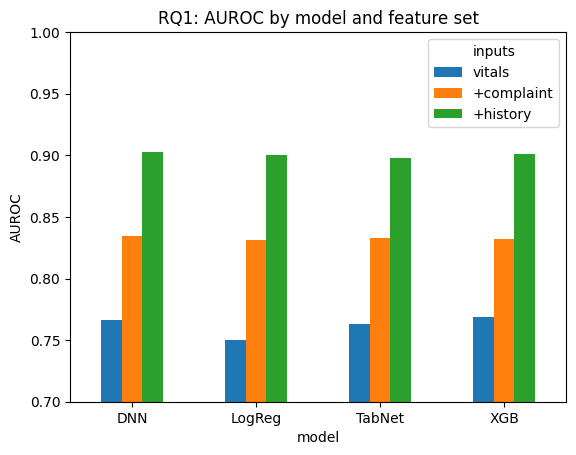

In [28]:
res=pd.DataFrame(results).T.round(4); res.to_csv('results_summary.csv'); print(res)
res['model']=[i.split('|')[0] for i in res.index]; res['inputs']=[i.split('|')[1] for i in res.index]
piv=res.pivot_table(index='model',columns='inputs',values='AUROC')
piv=piv[['vitals','+complaint','+history']]
print('\nRQ1 AUROC by input richness:'); print(piv.round(4))
piv.round(4).to_csv('rq1_auroc_by_model_inputs.csv')
piv.plot(kind='bar',title='RQ1: AUROC by model and feature set'); plt.ylim(.7,1)
plt.xticks(rotation=0); plt.ylabel('AUROC'); plt.savefig('rq1.png',dpi=120,bbox_inches='tight'); plt.show()

In [29]:
# Bootstrap significance: best model, vitals vs +history
def boot(yt,pa,pb_,n=1000):
    rng=np.random.default_rng(SEED); d=[]
    for _ in range(n):
        s=rng.integers(0,len(yt),len(yt))
        if len(np.unique(yt[s]))<2: continue
        d.append(roc_auc_score(yt[s],pb_[s])-roc_auc_score(yt[s],pa[s]))
    d=np.array(d); return d.mean(),np.percentile(d,2.5),np.percentile(d,97.5)
if 'XGB|vitals' in probs and 'XGB|+history' in probs:
    m,lo,hi=boot(y_te,probs['XGB|vitals'],probs['XGB|+history'])
    print(f'XGB improvement (+history vs vitals): {m:.4f} 95% CI [{lo:.4f},{hi:.4f}]')
    print('Significant' if lo>0 else 'Not significant')
    pd.DataFrame([{'comparison':'XGB +history vs vitals','mean_diff':m,'ci_low':lo,'ci_high':hi,
        'significant':lo>0}]).to_csv('bootstrap_significance.csv',index=False)

XGB improvement (+history vs vitals): 0.1330 95% CI [0.1262,0.1393]
Significant


## 6 — RQ2 (nurse ESI agreement), RQ3 (fairness), Error Analysis

In [ ]:
# Using the best model's predictions
best_key = max(probs, key=lambda k: results[k]['AUROC'])
p_best = probs[best_key]; pred=(p_best>=.5).astype(int)
print("Best model:", best_key)

# RQ2: agreement with nurse ESI (ESI 1-2 = high urgency vs actual admission)
mask=~pd.isna(esi_te)
esi_urgent=(esi_te[mask]<=2).astype(int)
kap=cohen_kappa_score(esi_urgent, pred[mask])
under_triage=((pred[mask]==0)&(y_te[mask]==1)).mean()
over_triage=((pred[mask]==1)&(y_te[mask]==0)).mean()
print(f"\nRQ2 kappa (model admit vs nurse-urgent ESI1-2): {kap:.3f}  (human benchmark 0.786)")
print("under-triage",round(under_triage,3),"| over-triage",round(over_triage,3))
pd.DataFrame([{'best_model':best_key,'kappa':round(kap,3),'human_benchmark_kappa':0.786,
    'under_triage':round(under_triage,3),'over_triage':round(over_triage,3)}]).to_csv('rq2_esi_agreement.csv',index=False)

Best model: DNN|+history

RQ2 kappa (model admit vs nurse-urgent ESI1-2): 0.368  (human benchmark 0.786)
under-triage 0.062 | over-triage 0.109


In [31]:
# RQ3: subgroup AUROC
sub=df.iloc[i_te].copy(); sub['p']=p_best; sub['y']=y_te
print("RQ3 subgroup AUROC:")
rq3_rows=[]
for n,mk in {'age<65':sub['age']<65,'age65+':sub['age']>=65}.items():
    g=sub[mk]
    if g['y'].nunique()==2:
        auc=roc_auc_score(g['y'],g['p']); print(f"  {n}: {auc:.4f}")
        rq3_rows.append({'subgroup_type':'age','subgroup':n,'auroc':round(auc,4)})
for v in sub['gender'].dropna().unique():
    g=sub[sub['gender']==v]
    if g['y'].nunique()==2:
        auc=roc_auc_score(g['y'],g['p']); print(f"  gender={v}: {auc:.4f}")
        rq3_rows.append({'subgroup_type':'gender','subgroup':v,'auroc':round(auc,4)})
pd.DataFrame(rq3_rows).to_csv('rq3_subgroup_auroc.csv',index=False)

RQ3 subgroup AUROC:
  age<65: 0.8868
  age65+: 0.8823
  gender=Male: 0.9018
  gender=Female: 0.9031


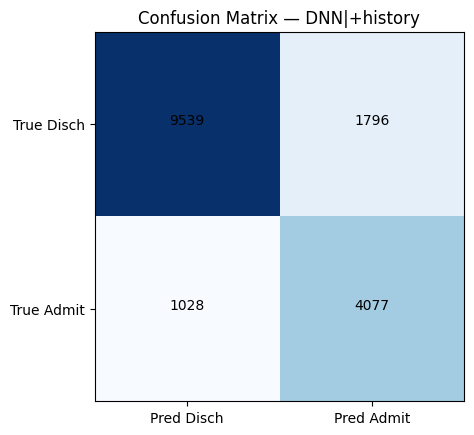

              precision    recall  f1-score   support

   Discharge       0.90      0.84      0.87     11335
       Admit       0.69      0.80      0.74      5105

    accuracy                           0.83     16440
   macro avg       0.80      0.82      0.81     16440
weighted avg       0.84      0.83      0.83     16440


Missed admissions (FN): 1028 | Caught (TP): 4077

Mean vitals: missed vs caught admissions:
                   Missed(FN)  Caught(TP)
triage_vital_hr         85.58       88.88
triage_vital_sbp       136.33      135.08
triage_vital_dbp        81.99       78.22
triage_vital_rr         17.63       18.10
triage_vital_o2         97.16       96.44
triage_vital_temp       98.15       98.20
age                     51.60       66.42
esi                      2.63        2.38


In [32]:
# Error analysis
cm=confusion_matrix(y_te,pred)
plt.imshow(cm,cmap='Blues')
for (i,j),v in np.ndenumerate(cm): plt.text(j,i,int(v),ha='center')
plt.xticks([0,1],['Pred Disch','Pred Admit']); plt.yticks([0,1],['True Disch','True Admit'])
plt.title(f'Confusion Matrix — {best_key}'); plt.savefig('confusion_matrix.png',dpi=120,bbox_inches='tight'); plt.show()
pd.DataFrame(cm,index=['True Disch','True Admit'],columns=['Pred Disch','Pred Admit']).to_csv('confusion_matrix.csv')

print(classification_report(y_te,pred,target_names=['Discharge','Admit']))
pd.DataFrame(classification_report(y_te,pred,target_names=['Discharge','Admit'],output_dict=True)).T.to_csv('classification_report.csv')

# Characterise false negatives (missed admissions -- clinically dangerous)
err=df.iloc[i_te].copy(); err['y']=y_te; err['pred']=pred
fn=err[(err['y']==1)&(err['pred']==0)]; tp=err[(err['y']==1)&(err['pred']==1)]
print(f"\nMissed admissions (FN): {len(fn)} | Caught (TP): {len(tp)}")
cmp=[c for c in vitals+['age','esi'] if c in err.columns]
print("\nMean vitals: missed vs caught admissions:")
missed_vs_caught = pd.concat([fn[cmp].mean(),tp[cmp].mean()],axis=1,keys=['Missed(FN)','Caught(TP)']).round(2)
print(missed_vs_caught)
missed_vs_caught.to_csv('missed_vs_caught_vitals.csv')